# 기능 D 굿즈 보존 배경: 방식 비교 (10/28)

무지 굿즈 사진의 굿즈는 그대로 두고 배경·연출만 새로 만든다. 10/28 조사한 후보(Notion D 페이지 "굿즈 보존 배경 방식 후보")를 같은 입력으로 비교한다. D는 기본 방식만 구현하기로 했고(10/28), 가설은 D1(마스크 인페인팅)이 가장 낫다는 것이다.

| 후보 | 방식 | 근거 |
|---|---|---|
| D1 | BiRefNet 굿즈 마스크 밖(배경)만 SDXL 인페인팅(strength 1.0)으로 새로 그리고, 굿즈는 원본 픽셀을 마스크 알파로 다시 덮어씀 | diffusers 인페인팅 문서 "White pixels in the mask are repainted while black pixels are preserved". VAE를 거치며 바뀌는지는 문서에 없어 다시 덮어씀 |
| D2 | IC-Light 배경 조건 모델(iclight_sd15_fbc): 굿즈(전경)와 배경 이미지를 넣어 조명이 맞는 전체 이미지를 다시 그림. 배경 이미지는 같은 장면 문구로 SDXL이 만든 빈 배경 | IC-Light README "background-conditioned model", 공식 데모 `gradio_demo_bg.py`(커밋 bcf3f29)의 처리 순서와 기본값을 그대로 옮김. 데모의 BRIA RMBG 대신 D1과 같은 BiRefNet 마스크를 씀 |

- D2는 굿즈까지 다시 그려 조명을 맞추는 방식이라 굿즈가 원본과 얼마나 같은지를 지표로 잰다. D1은 굿즈를 원본으로 덮어써 굿즈 보존은 거의 1이고, 대신 경계와 조명이 어색할 수 있어 그림으로 확인한다.
- 굿즈 영역: BiRefNet(MIT) 마스크. 모델 코드에 einops·kornia·timm이 필요하고("의존성 설치" 셀), 불러오지 못하면 멈춘다(가장자리 색 기준 대체 마스크는 흰 굿즈·흰 배경 사진에서 틀려 14에서 확인, `ALLOW_MASK_FALLBACK = True`로만 씀).
- 입력: 03 "4-1"에서 받은 무지 굿즈 사진 11장(긴 변 1024) × 장면 문구 3개(아래 `SCENES`, 탐색값), seed 0
- 지표
  - 굿즈 보존: 굿즈 마스크(4px 줄임) 안 원본 대비 SSIM·PSNR (`prod_ssim`, `prod_psnr`)
  - 장면 반영: 결과 이미지와 장면 문구의 CLIP 유사도 (`scene_sim`)
  - 육안: 장면별 비교 그림(경계 번짐, 조명·그림자)
- 탐색값(근거 문서 없음): 장면 문구 3개, D1 strength 1.0·30스텝·CFG 7·마스크 경계 2px 줄임. D2는 데모 기본값(20스텝, CFG 7, 고해상도 1.5배·denoise 0.5, 긴 변 640)
- 기록 (`outputs/background_d/`)
  - `d_config.json`: 후보별 설정 전문, 장면 문구, 입력 목록, 패키지 버전, GPU
  - `masks.csv`, `masks/`, `backgrounds/`(D2 배경)
  - `d_records.csv`: 이미지 1장마다 방식·굿즈·장면·설정·생성 시간·최대 VRAM·오류
  - `d_runs.csv`: 단계마다 시작·종료 시각, 모델 로드 시간, 전체 시간, 장수
  - `d_scored.csv`, `d_summary.csv`, `d_scores.png`, `d_grid_<장면>.png`
- 실행 순서: 위에서부터 차례로. 다시 실행하면 오류 없이 만든 이미지는 건너뛴다.
- 예상 시간(추정): 마스크 1분, D1 33장 × 약 10초 ≈ 6분, D2 33장 × 약 5초 + 첫 다운로드(Realistic Vision v5.1, IC-Light 가중치 약 1.7GB)
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 의존성 설치

In [1]:
# BiRefNet 모델 코드가 einops·kornia·timm을 씀 (없으면 불러오기 실패). 설치 후 커널 재시작
%pip install einops kornia timm

Note: you may need to restart the kernel to use updated packages.


## 설정

In [2]:
import gc
import importlib.metadata
import json
import math
import os
import platform
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

ROOT = Path('..')
OUT_DIR = ROOT / 'outputs' / 'background_d'
OUT_DIR.mkdir(parents=True, exist_ok=True)
BG_DIR = OUT_DIR / 'backgrounds'
BG_DIR.mkdir(exist_ok=True)
REC_CSV = OUT_DIR / 'd_records.csv'
RUNS_CSV = OUT_DIR / 'd_runs.csv'

GOODS_DIR = ROOT / 'data' / 'raw' / 'goods'
SRC_CSV = GOODS_DIR / 'goods_sources.csv'
assert SRC_CSV.exists(), '굿즈 사진이 없음 → 03 "4-1. 무료 사진 사이트에서 무지 굿즈 사진 받기" 셀을 먼저 실행'
GOODS = pd.read_csv(SRC_CSV, keep_default_na=False)
GOODS = GOODS[(GOODS.error == '') & GOODS.file.map(lambda f: (GOODS_DIR / f).exists())].reset_index(drop=True)
assert len(GOODS), '받은 굿즈 사진이 없음'
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
# 원본 사진은 4000px 이상이라 긴 변 1024(8의 배수)로 줄여 모든 방식에 같은 입력으로 씀
MAX_SIDE = 1024


def load_goods(name):
    im = Image.open(GOODS_DIR / name).convert('RGB')
    s = MAX_SIDE / max(im.size)
    w, h = (int(round(im.width * s / 8)) * 8, int(round(im.height * s / 8)) * 8)
    return im.resize((w, h), Image.LANCZOS)


print('굿즈', len(GOODS), '장:', GOODS.groupby('kind').size().to_dict())

SDXL_BASE = 'stabilityai/stable-diffusion-xl-base-1.0'
SD15 = 'stablediffusionapi/realistic-vision-v51'
ICLIGHT = dict(repo='lllyasviel/ic-light', file='iclight_sd15_fbc.safetensors', code_commit='bcf3f29ca85be8a4686215f477b546f5030be8b7')
SEED = 0
# 장면 문구 (탐색값)
SCENES = {
    'desk': 'on a wooden desk next to a game controller and small figures, warm desk lamp light, cozy room',
    'studio': 'on a pastel color studio backdrop, soft shadow, clean background',
    'cafe': 'on a cafe table by the window, morning sunlight, shallow depth of field',
}
D1_ARGS = dict(strength=1.0, steps=30, cfg=7.0, mask_erode_px=2)
# D2 배경 이미지 크기 (IC-Light가 굿즈 비율에 맞춰 가운데를 잘라 씀)
BG_SIZE = 1024
# IC-Light 데모(gradio_demo_bg.py) 기본값
D2_ARGS = dict(steps=20, cfg=7.0, highres_scale=1.5, highres_denoise=0.5, max_side=640, a_prompt='best quality',
               n_prompt='lowres, bad anatomy, bad hands, cropped, worst quality')
NEGATIVE = 'text, letters, watermark, logo, lowres, blurry, deformed'


def scene_prompt(kind, scene):
    return f'product photography of a {KIND_EN[kind]} {SCENES[scene]}'


def out_name(method, name, scene):
    return f'{method}__{Path(name).stem}__{scene}.png'


recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f):
    return recs.get(f, {}).get('error', 'x') == '' and (OUT_DIR / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


def erode(m, px):
    return np.asarray(Image.fromarray((m * 255).astype(np.uint8)).filter(ImageFilter.MinFilter(2 * px + 1))) / 255.0

def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


def append_csv(path, rec):
    pd.DataFrame([rec]).to_csv(path, mode='a', header=not path.exists(), index=False, encoding='utf-8-sig')

굿즈 11 장: {'hoodie': 2, 'mug': 4, 'tote': 3, 'tshirt': 2}


## 굿즈 마스크

In [3]:
MASK_DIR = OUT_DIR / 'masks'
MASK_DIR.mkdir(exist_ok=True)
BIREFNET = 'ZhengPeng7/BiRefNet'
# 가장자리 색 기준 대체 마스크는 흰 굿즈·흰 배경 사진에서 틀림(10/28 확인) → 기본은 쓰지 않고 멈춤
ALLOW_MASK_FALLBACK = False


def mask_fallback(img):
    # BiRefNet을 못 쓸 때: 사진 가장자리 색(무지 배경)과 다른 픽셀을 굿즈로 봄
    a = np.asarray(img).astype(np.float32)
    border = np.concatenate([a[:8].reshape(-1, 3), a[-8:].reshape(-1, 3), a[:, :8].reshape(-1, 3), a[:, -8:].reshape(-1, 3)])
    d = np.linalg.norm(a - np.median(border, 0), axis=2)
    return (d > 30).astype(np.float32)


def make_masks():
    import torch
    # 이미 만든 마스크(파일과 masks.csv 기록이 모두 있는 사진)는 건너뜀
    old = pd.read_csv(OUT_DIR / 'masks.csv', keep_default_na=False) if (OUT_DIR / 'masks.csv').exists() else pd.DataFrame(columns=['file'])
    todo = [g for g in GOODS.itertuples() if g.file not in set(old.file) or not (MASK_DIR / f'{Path(g.file).stem}.png').exists()]
    print('마스크 새로 만들 사진', len(todo), '/', len(GOODS))
    if not todo:
        return old[old.file.isin(GOODS.file)].reset_index(drop=True)
    rows, model, method = [], None, 'birefnet'
    try:
        from torchvision import transforms
        from transformers import AutoModelForImageSegmentation
        model = AutoModelForImageSegmentation.from_pretrained(BIREFNET, trust_remote_code=True).to('cuda').eval().float()
        tf = transforms.Compose([transforms.Resize((1024, 1024)), transforms.ToTensor(),
                                 transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    except Exception as e:
        if not ALLOW_MASK_FALLBACK:
            raise RuntimeError('BiRefNet을 불러오지 못함 → "의존성 설치" 셀(einops, kornia, timm) 실행 후 커널 재시작: '
                               f'{type(e).__name__}: {str(e)[:200]}') from e
        method = f'fallback ({type(e).__name__}: {str(e)[:120]})'
        print('BiRefNet 불러오기 실패 → 가장자리 색 기준 마스크로 대체:', method)
    for g in todo:
        img = load_goods(g.file)
        t0 = time.perf_counter()
        if model is not None:
            with torch.no_grad():
                pred = model(tf(img).unsqueeze(0).to('cuda'))[-1].sigmoid()[0, 0].float().cpu().numpy()
            m = np.asarray(Image.fromarray((pred * 255).astype(np.uint8)).resize(img.size, Image.BILINEAR)) / 255.0
        else:
            m = mask_fallback(img)
        Image.fromarray((m * 255).astype(np.uint8)).save(MASK_DIR / f'{Path(g.file).stem}.png')
        rows.append(dict(file=g.file, kind=g.kind, mask_method=method, mask_area=round(float((m > 0.5).mean()), 4),
                         sec=round(time.perf_counter() - t0, 2), width=img.width, height=img.height))
    if model is not None:
        del model
        gc.collect()
        torch.cuda.empty_cache()
    new = pd.DataFrame(rows)
    return pd.concat([old[old.file.isin(GOODS.file) & ~old.file.isin(new.file)], new], ignore_index=True)


def load_mask(name):
    return np.asarray(Image.open(MASK_DIR / f'{Path(name).stem}.png')).astype(np.float32) / 255.0


masks = make_masks()
masks.to_csv(OUT_DIR / 'masks.csv', index=False, encoding='utf-8-sig')
display(masks)

마스크 새로 만들 사진 0 / 11


,file,kind,mask_method,mask_area,sec,width,height
0,mug_01.jpg,mug,birefnet,0.1950,0.93,888.0,1024.0
1,mug_02.jpg,mug,birefnet,0.2262,0.38,1024.0,680.0
2,mug_03.jpg,mug,birefnet,0.0985,0.38,1024.0,680.0
3,mug_04.jpg,mug,birefnet,0.1858,0.39,1024.0,680.0
4,tshirt_01.jpg,tshirt,birefnet,0.2570,0.41,1024.0,680.0
5,tshirt_02.jpg,tshirt,birefnet,0.2505,0.44,1024.0,680.0
6,tote_01.jpg,tote,birefnet,0.2416,0.44,1024.0,680.0
7,tote_02.jpg,tote,birefnet,0.2408,0.44,680.0,1024.0
8,tote_03.jpg,tote,birefnet,0.1282,0.43,576.0,1024.0
9,hoodie_01.jpg,hoodie,birefnet,0.3183,0.43,1024.0,768.0


## D1 마스크 인페인팅 + D2 배경 (SDXL)

In [4]:
import torch
from diffusers import StableDiffusionXLInpaintPipeline, StableDiffusionXLPipeline

todo1 = [(g, sc) for g in GOODS.itertuples() for sc in SCENES if not done(out_name('D1', g.file, sc))]
todo_bg = [sc for sc in SCENES if not (BG_DIR / f'{sc}.png').exists()]
print('D1', len(todo1), '장 | D2 배경', len(todo_bg), '장')
if todo1 or todo_bg:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    pipe = StableDiffusionXLInpaintPipeline.from_pretrained(SDXL_BASE, torch_dtype=torch.bfloat16).to('cuda')
    load_sec = round(time.perf_counter() - t_all, 1)
    peak = 0.0
    for g, sc in todo1:
        f = out_name('D1', g.file, sc)
        img = load_goods(g.file)
        alpha = load_mask(g.file)
        # 배경 + 굿즈 경계 2px까지 다시 그리고, 굿즈는 원본을 마스크 알파로 덮어씀
        bg_mask = 1 - erode((alpha > 0.5).astype(np.float32), D1_ARGS['mask_erode_px'])
        rec = dict(file=f, method='D1', goods=g.file, kind=g.kind, scene=sc, params=json.dumps(
            dict(D1_ARGS, prompt=scene_prompt(g.kind, sc), negative=NEGATIVE)), error='')
        try:
            torch.cuda.reset_peak_memory_stats()
            t0 = time.perf_counter()
            out = pipe(prompt=scene_prompt(g.kind, sc), negative_prompt=NEGATIVE, image=img,
                       mask_image=Image.fromarray((bg_mask * 255).astype(np.uint8)), strength=D1_ARGS['strength'],
                       num_inference_steps=D1_ARGS['steps'], guidance_scale=D1_ARGS['cfg'], width=img.width, height=img.height,
                       generator=torch.Generator('cpu').manual_seed(SEED)).images[0].resize(img.size)
            a = alpha[..., None]
            res = np.asarray(img, dtype=np.float64) * a + np.asarray(out, dtype=np.float64) * (1 - a)
            Image.fromarray(res.clip(0, 255).astype(np.uint8)).save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            peak = max(peak, rec['peak_vram_gb'])
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
        print(f, rec.get('sec'), rec['error'][:100], flush=True)
    # D2용 빈 배경 (같은 장면 문구, 굿즈 없음)
    if todo_bg:
        t2i = StableDiffusionXLPipeline.from_pipe(pipe)
        for sc in todo_bg:
            t0 = time.perf_counter()
            bg = t2i(prompt=f'{SCENES[sc]}, empty scene, no objects', negative_prompt=NEGATIVE + ', product, object in center',
                     num_inference_steps=D1_ARGS['steps'], guidance_scale=D1_ARGS['cfg'], width=BG_SIZE, height=BG_SIZE,
                     generator=torch.Generator('cpu').manual_seed(SEED)).images[0]
            bg.save(BG_DIR / f'{sc}.png')
            print('배경', sc, round(time.perf_counter() - t0, 1), '초', flush=True)
        del t2i
    append_csv(RUNS_CSV, dict(stage='D1 + D2 배경 (SDXL)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=len(todo1) + len(todo_bg),
                              load_sec=load_sec, peak_vram_gb=peak))
    del pipe
    gc.collect()
    torch.cuda.empty_cache()

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1028 17:48:12.741000 60532 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1028 17:48:12.829000 60532 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading 

D1 30 장 | D2 배경 3 장


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 7/7 [00:06<00:00,  1.02it/s]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules 

D1__mug_02__desk.png 8.32 


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 30/30 [00:06<00:00,  4.34it/s]


D1__mug_02__studio.png 7.96 


... (58 outputs left out)

100%|██████████| 30/30 [02:35<00:00,  5.19s/it]


배경 studio 159.2 초


100%|██████████| 30/30 [02:36<00:00,  5.22s/it]


배경 cafe 160.1 초


## D2 IC-Light 배경 조건 재조명

In [5]:
# IC-Light 공식 데모 gradio_demo_bg.py(커밋 bcf3f29)의 모델 준비·process()를 옮김. 바꾼 점: 배경 제거(BRIA RMBG) 대신 BiRefNet 마스크
import safetensors.torch as sf
from diffusers import AutoencoderKL, DPMSolverMultistepScheduler, StableDiffusionImg2ImgPipeline, StableDiffusionPipeline, UNet2DConditionModel
from diffusers.models.attention_processor import AttnProcessor2_0
from huggingface_hub import hf_hub_download
from transformers import CLIPTextModel, CLIPTokenizer

todo2 = [(g, sc) for g in GOODS.itertuples() for sc in SCENES if not done(out_name('D2', g.file, sc))]
print('D2', len(todo2), '장')


def load_iclight():
    tokenizer = CLIPTokenizer.from_pretrained(SD15, subfolder='tokenizer')
    text_encoder = CLIPTextModel.from_pretrained(SD15, subfolder='text_encoder')
    vae = AutoencoderKL.from_pretrained(SD15, subfolder='vae')
    unet = UNet2DConditionModel.from_pretrained(SD15, subfolder='unet')
    with torch.no_grad():
        new_conv_in = torch.nn.Conv2d(12, unet.conv_in.out_channels, unet.conv_in.kernel_size, unet.conv_in.stride, unet.conv_in.padding)
        new_conv_in.weight.zero_()
        new_conv_in.weight[:, :4, :, :].copy_(unet.conv_in.weight)
        new_conv_in.bias = unet.conv_in.bias
        unet.conv_in = new_conv_in
    unet_original_forward = unet.forward

    def hooked_unet_forward(sample, timestep, encoder_hidden_states, **kwargs):
        c_concat = kwargs['cross_attention_kwargs']['concat_conds'].to(sample)
        c_concat = torch.cat([c_concat] * (sample.shape[0] // c_concat.shape[0]), dim=0)
        new_sample = torch.cat([sample, c_concat], dim=1)
        kwargs['cross_attention_kwargs'] = {}
        return unet_original_forward(new_sample, timestep, encoder_hidden_states, **kwargs)

    unet.forward = hooked_unet_forward
    sd_offset = sf.load_file(hf_hub_download(ICLIGHT['repo'], ICLIGHT['file']))
    sd_origin = unet.state_dict()
    unet.load_state_dict({k: sd_origin[k] + sd_offset[k] for k in sd_origin.keys()}, strict=True)
    del sd_offset, sd_origin
    text_encoder = text_encoder.to(device='cuda', dtype=torch.float16)
    vae = vae.to(device='cuda', dtype=torch.bfloat16)
    unet = unet.to(device='cuda', dtype=torch.float16)
    unet.set_attn_processor(AttnProcessor2_0())
    vae.set_attn_processor(AttnProcessor2_0())
    sched = DPMSolverMultistepScheduler(num_train_timesteps=1000, beta_start=0.00085, beta_end=0.012,
                                        algorithm_type='sde-dpmsolver++', use_karras_sigmas=True, steps_offset=1)
    kw = dict(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet, scheduler=sched, safety_checker=None,
              requires_safety_checker=False, feature_extractor=None, image_encoder=None)
    return tokenizer, text_encoder, vae, StableDiffusionPipeline(**kw), StableDiffusionImg2ImgPipeline(**kw)


@torch.inference_mode()
def encode_prompt_inner(txt):
    max_length = tokenizer.model_max_length
    chunk_length = tokenizer.model_max_length - 2
    id_start, id_end = tokenizer.bos_token_id, tokenizer.eos_token_id

    def pad(x, p, i):
        return x[:i] if len(x) >= i else x + [p] * (i - len(x))

    tokens = tokenizer(txt, truncation=False, add_special_tokens=False)['input_ids']
    chunks = [[id_start] + tokens[i: i + chunk_length] + [id_end] for i in range(0, len(tokens), chunk_length)]
    chunks = [pad(ck, id_end, max_length) for ck in chunks]
    return text_encoder(torch.tensor(chunks).to(device='cuda', dtype=torch.int64)).last_hidden_state


@torch.inference_mode()
def encode_prompt_pair(positive_prompt, negative_prompt):
    c, uc = encode_prompt_inner(positive_prompt), encode_prompt_inner(negative_prompt)
    max_count = max(float(len(c)), float(len(uc)))
    max_chunk = max(len(c), len(uc))
    c = torch.cat([c] * int(math.ceil(max_count / len(c))), dim=0)[:max_chunk]
    uc = torch.cat([uc] * int(math.ceil(max_count / len(uc))), dim=0)[:max_chunk]
    return torch.cat([p[None, ...] for p in c], dim=1), torch.cat([p[None, ...] for p in uc], dim=1)


@torch.inference_mode()
def pytorch2numpy(imgs, quant=True):
    out = []
    for x in imgs:
        y = x.movedim(0, -1)
        if quant:
            out.append((y * 127.5 + 127.5).detach().float().cpu().numpy().clip(0, 255).astype(np.uint8))
        else:
            out.append((y * 0.5 + 0.5).detach().float().cpu().numpy().clip(0, 1).astype(np.float32))
    return out


@torch.inference_mode()
def numpy2pytorch(imgs):
    return (torch.from_numpy(np.stack(imgs, axis=0)).float() / 127.0 - 1.0).movedim(-1, 1)


def resize_and_center_crop(image, tw, th):
    pil = Image.fromarray(image)
    s = max(tw / pil.width, th / pil.height)
    rw, rh = int(round(pil.width * s)), int(round(pil.height * s))
    pil = pil.resize((rw, rh), Image.LANCZOS)
    return np.array(pil.crop(((rw - tw) / 2, (rh - th) / 2, (rw + tw) / 2, (rh + th) / 2)))


def resize_without_crop(image, tw, th):
    return np.array(Image.fromarray(image).resize((tw, th), Image.LANCZOS))


@torch.inference_mode()
def process(input_fg, input_bg, prompt, w, h, seed, steps, a_prompt, n_prompt, cfg, highres_scale, highres_denoise):
    rng = torch.Generator(device='cuda').manual_seed(seed)
    fg, bg = resize_and_center_crop(input_fg, w, h), resize_and_center_crop(input_bg, w, h)
    cc = vae.encode(numpy2pytorch([fg, bg]).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    cc = torch.cat([c[None, ...] for c in cc], dim=1)
    conds, unconds = encode_prompt_pair(prompt + ', ' + a_prompt, n_prompt)
    latents = t2i_pipe(prompt_embeds=conds, negative_prompt_embeds=unconds, width=w, height=h, num_inference_steps=steps,
                       num_images_per_prompt=1, generator=rng, output_type='latent', guidance_scale=cfg,
                       cross_attention_kwargs={'concat_conds': cc}).images.to(vae.dtype) / vae.config.scaling_factor
    pixels = pytorch2numpy(vae.decode(latents).sample)
    pixels = [resize_without_crop(p, int(round(w * highres_scale / 64.0) * 64), int(round(h * highres_scale / 64.0) * 64)) for p in pixels]
    latents = vae.encode(numpy2pytorch(pixels).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    latents = latents.to(device=t2i_pipe.unet.device, dtype=t2i_pipe.unet.dtype)
    h2, w2 = latents.shape[2] * 8, latents.shape[3] * 8
    fg, bg = resize_and_center_crop(input_fg, w2, h2), resize_and_center_crop(input_bg, w2, h2)
    cc = vae.encode(numpy2pytorch([fg, bg]).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    cc = torch.cat([c[None, ...] for c in cc], dim=1)
    latents = i2i_pipe(image=latents, strength=highres_denoise, prompt_embeds=conds, negative_prompt_embeds=unconds, width=w2,
                       height=h2, num_inference_steps=int(round(steps / highres_denoise)), num_images_per_prompt=1, generator=rng,
                       output_type='latent', guidance_scale=cfg,
                       cross_attention_kwargs={'concat_conds': cc}).images.to(vae.dtype) / vae.config.scaling_factor
    return pytorch2numpy(vae.decode(latents).sample, quant=False)[0]


if todo2:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    tokenizer, text_encoder, vae, t2i_pipe, i2i_pipe = load_iclight()
    load_sec = round(time.perf_counter() - t_all, 1)
    print('IC-Light 로드', load_sec, '초', flush=True)
    peak = 0.0
    for g, sc in todo2:
        f = out_name('D2', g.file, sc)
        img = load_goods(g.file)
        s = D2_ARGS['max_side'] / max(img.size)
        w, h = int(round(img.width * s / 64)) * 64, int(round(img.height * s / 64)) * 64
        alpha = load_mask(g.file)[..., None]
        # 데모 run_rmbg와 같은 회색(127) 배경 전경
        fg = (127 + (np.asarray(img, dtype=np.float32) - 127) * alpha).clip(0, 255).astype(np.uint8)
        bg = np.asarray(Image.open(BG_DIR / f'{sc}.png').convert('RGB'))
        rec = dict(file=f, method='D2', goods=g.file, kind=g.kind, scene=sc, params=json.dumps(
            dict(D2_ARGS, prompt=scene_prompt(g.kind, sc), width=w, height=h, sd15=SD15, iclight=ICLIGHT)), error='')
        try:
            torch.cuda.reset_peak_memory_stats()
            t0 = time.perf_counter()
            res = process(fg, bg, scene_prompt(g.kind, sc), w, h, SEED, D2_ARGS['steps'], D2_ARGS['a_prompt'], D2_ARGS['n_prompt'],
                          D2_ARGS['cfg'], D2_ARGS['highres_scale'], D2_ARGS['highres_denoise'])
            Image.fromarray((res * 255).clip(0, 255).astype(np.uint8)).save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            peak = max(peak, rec['peak_vram_gb'])
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
        print(f, rec.get('sec'), rec['error'][:100], flush=True)
    append_csv(RUNS_CSV, dict(stage='D2 (IC-Light)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=len(todo2), load_sec=load_sec, peak_vram_gb=peak))
    del t2i_pipe, i2i_pipe, text_encoder, vae
    gc.collect()
    torch.cuda.empty_cache()

config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), goods=GOODS[['file', 'kind', 'site', 'page']].to_dict('records'), max_side=MAX_SIDE,
    mask_model=BIREFNET, scenes=SCENES, prompt_example=scene_prompt('tshirt', 'desk'), negative=NEGATIVE, seed=SEED,
    D1=dict(model=SDXL_BASE, **D1_ARGS), D2=dict(sd15=SD15, iclight=ICLIGHT, **D2_ARGS, background='SDXL t2i: scene + "empty scene, no objects"'),
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'accelerate', 'safetensors', 'pillow', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'd_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
dr = pd.read_csv(REC_CSV, keep_default_na=False)
print('기록', len(dr), '장 | 오류', (dr.error != '').sum())

D2 33 장


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrator\.cache\huggingface\hub\models--stablediffusionapi--realistic-vision-v51. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_h

IC-Light 로드 70.4 초


100%|██████████| 20/20 [00:04<00:00,  4.53it/s]


D2__mug_01__desk.png 8.19 


100%|██████████| 20/20 [00:04<00:00,  4.54it/s]


... (59 outputs left out)

100%|██████████| 20/20 [00:02<00:00,  7.07it/s]


D2__hoodie_02__studio.png 4.96 


100%|██████████| 20/20 [00:02<00:00,  7.16it/s]


D2__hoodie_02__cafe.png 4.88 
기록 66 장 | 오류 0


## 지표

In [6]:
def _box(x, r=3):
    # 7×7 평균 필터 (누적합)
    p = np.pad(x, r + 1, mode='edge')
    c = p.cumsum(0).cumsum(1)
    k = 2 * r + 1
    return (c[k:, k:] - c[:-k, k:] - c[k:, :-k] + c[:-k, :-k])[:x.shape[0], :x.shape[1]] / (k * k)


def ssim_map(a, b):
    # 회색조 SSIM (Wang et al. 2004 상수, 7×7 평균 창)
    a = np.asarray(a.convert('L'), dtype=np.float64)
    b = np.asarray(b.convert('L'), dtype=np.float64)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    ma, mb = _box(a), _box(b)
    va, vb, cov = _box(a * a) - ma ** 2, _box(b * b) - mb ** 2, _box(a * b) - ma * mb
    return ((2 * ma * mb + c1) * (2 * cov + c2)) / ((ma ** 2 + mb ** 2 + c1) * (va + vb + c2))


def psnr(a, b, region):
    d = (np.asarray(a, dtype=np.float64) - np.asarray(b, dtype=np.float64))[region]
    mse = (d ** 2).mean()
    # 완전히 같으면 무한대 → 평균을 낼 수 있게 100dB로 둠
    return 100.0 if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


def unit(e):
    e = feat(e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


with torch.no_grad():
    SCENE_E = dict(zip(SCENES, unit(clip.get_text_features(**clip_proc(text=list(SCENES.values()), return_tensors='pt',
                                                                         padding=True, truncation=True).to('cuda')))))
dr = pd.read_csv(REC_CSV, keep_default_na=False)
dr = dr[dr.error == ''].reset_index(drop=True)
rows = []
for r in dr.itertuples():
    orig = load_goods(r.goods)
    out = Image.open(OUT_DIR / r.file).convert('RGB').resize(orig.size, Image.LANCZOS)
    prod = erode((load_mask(r.goods) > 0.5).astype(np.float32), 4) > 0.5
    s = ssim_map(orig, out)
    with torch.no_grad():
        e = unit(clip.get_image_features(**clip_proc(images=[out], return_tensors='pt').to('cuda')))[0]
    rows.append(dict(file=r.file, method=r.method, goods=r.goods, kind=r.kind, scene=r.scene, sec=float(r.sec),
                     prod_ssim=float(s[prod].mean()), prod_psnr=psnr(orig, out, prod), scene_sim=float(e @ SCENE_E[r.scene])))
ds = pd.DataFrame(rows)
ds.to_csv(OUT_DIR / 'd_scored.csv', index=False, encoding='utf-8-sig')
METHODS = [m for m in ['D1', 'D2'] if m in set(ds.method)]
summ = ds.groupby('method')[['prod_ssim', 'prod_psnr', 'scene_sim', 'sec']].agg(['mean', 'std']).reindex(METHODS)
summ.to_csv(OUT_DIR / 'd_summary.csv', encoding='utf-8-sig')
display(summ.round(3))
print('종류별 굿즈 보존(prod_ssim)·장면 반영(scene_sim)')
display(ds.pivot_table(index='method', columns='kind', values=['prod_ssim', 'scene_sim']).reindex(METHODS).round(3))

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19594.26it/s]


prod_ssim        prod_psnr        scene_sim           sec       
            mean    std      mean    std      mean    std   mean    std
method                                                                 
D1         0.998  0.001    53.020  3.204     0.254  0.027  8.250  1.297
D2         0.806  0.105    14.287  3.117     0.272  0.033  5.689  0.800

종류별 굿즈 보존(prod_ssim)·장면 반영(scene_sim)


prod_ssim                      scene_sim                     
kind      hoodie    mug   tote tshirt    hoodie    mug   tote tshirt
method                                                              
D1         0.998  0.998  0.998  0.998     0.239  0.278  0.243  0.239
D2         0.689  0.885  0.752  0.844     0.237  0.300  0.267  0.260

## 시각화

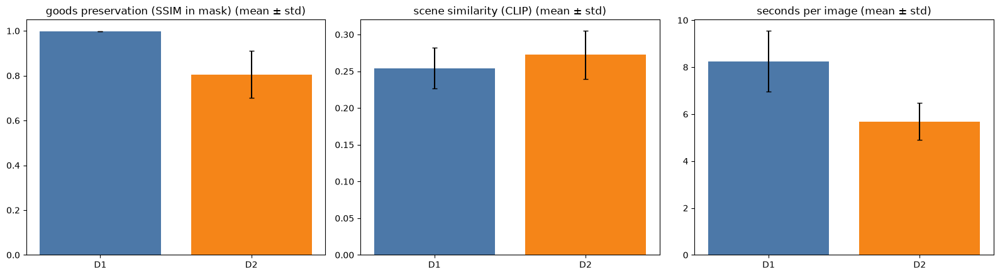

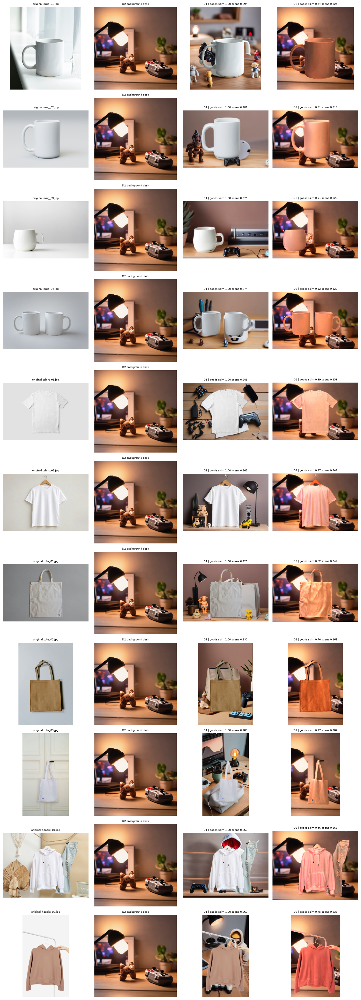

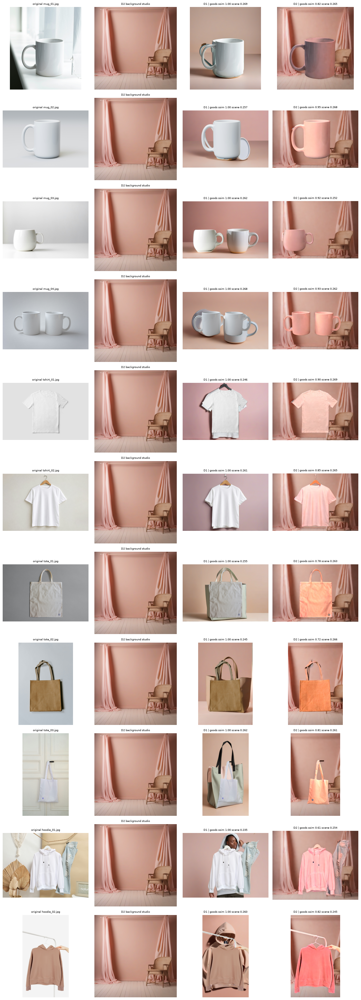

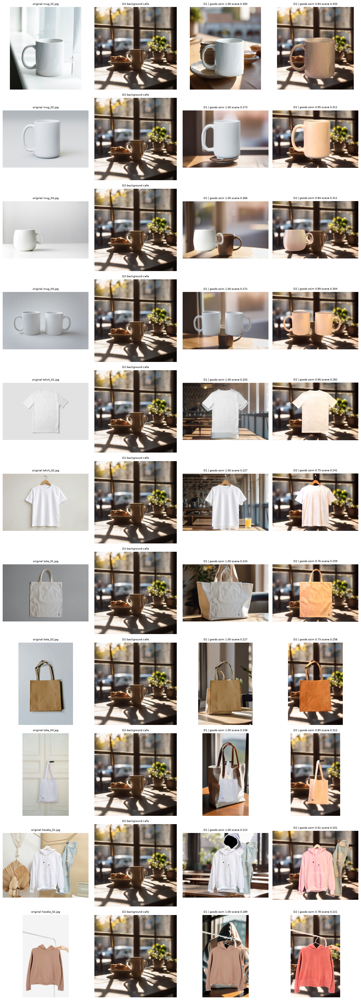

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = np.arange(len(METHODS))
for ax, col, title in zip(axes, ['prod_ssim', 'scene_sim', 'sec'],
                          ['goods preservation (SSIM in mask)', 'scene similarity (CLIP)', 'seconds per image']):
    ax.bar(x, summ[(col, 'mean')], yerr=summ[(col, 'std')].fillna(0), capsize=3, color=['#4C78A8', '#F58518'][:len(METHODS)])
    ax.set_xticks(x, METHODS)
    ax.set_title(f'{title} (mean ± std)')
axes[0].set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(OUT_DIR / 'd_scores.png', dpi=90)
plt.show()

# 장면별 비교: 행 = 굿즈, 열 = 원본 / D2 배경 / D1 / D2
for sc in SCENES:
    sub = GOODS.file.tolist()
    fig, axes = plt.subplots(len(sub), 2 + len(METHODS), figsize=(3.4 * (2 + len(METHODS)), 3.4 * len(sub)), squeeze=False)
    for i, name in enumerate(sub):
        axes[i, 0].imshow(load_goods(name))
        axes[i, 0].set_title(f'original {name}', fontsize=7)
        if (BG_DIR / f'{sc}.png').exists():
            axes[i, 1].imshow(Image.open(BG_DIR / f'{sc}.png'))
            axes[i, 1].set_title(f'D2 background {sc}', fontsize=7)
        for j, m in enumerate(METHODS):
            r = ds[(ds.goods == name) & (ds.scene == sc) & (ds.method == m)]
            if len(r):
                r = r.iloc[0]
                axes[i, j + 2].imshow(Image.open(OUT_DIR / r.file))
                axes[i, j + 2].set_title(f'{m} | goods ssim {r.prod_ssim:.2f} scene {r.scene_sim:.3f}', fontsize=7)
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'd_grid_{sc}.png', dpi=50)
    plt.show()